# Assignment: Spotify Song Clustering
### Task Description

The goal of this project is to group Spotify songs based on their similarities using the K-Means clustering algorithm.

The task includes preparing the dataset, selecting relevant features, determining the optimal number of clusters, and analyzing the resulting groups.


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import sklearn.cluster as cluster

# 1. Filtering Out Songs with Speechiness Above 60

In [2]:
# Keeping only songs with speechiness at or below 60, then inspecting the filtered dataset.
data = pd.read_csv('spotify.csv')
cl_data = data[data["speechiness"] <= 60].copy()

# 2. Selecting Features for Clustering

In [3]:
# Inspecting column types. The Spotify chart position is stored as an object and will be converted to numeric values.
cl_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 13 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   track_name            952 non-null    object 
 1   released_year         952 non-null    int64  
 2   in_spotify_playlists  952 non-null    int64  
 3   in_spotify_charts     951 non-null    object 
 4   streams               952 non-null    int64  
 5   in_apple_playlists    952 non-null    int64  
 6   in_apple_charts       950 non-null    float64
 7   bpm                   952 non-null    int64  
 8   mode                  952 non-null    object 
 9   energy                952 non-null    int64  
 10  instrumentalness      952 non-null    int64  
 11  liveness              952 non-null    int64  
 12  speechiness           952 non-null    int64  
dtypes: float64(1), int64(9), object(3)
memory usage: 104.1+ KB


In [4]:
# Reviewing descriptive statistics. Instrumentalness is mostly zero through the 75th percentile, while most release years are recent
cl_data.describe()

,released_year,in_spotify_playlists,streams,in_apple_playlists,in_apple_charts,bpm,energy,instrumentalness,liveness,speechiness
count,952.000000,952.000000,9.520000e+02,952.000000,950.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,2018.233193,5205.304622,5.146578e+08,67.876050,51.746316,122.555672,64.297269,1.582983,18.211134,10.074580
std,11.120988,7900.140377,5.666776e+08,86.464421,50.426462,28.068585,16.549733,8.414064,13.718308,9.762894
min,1930.000000,31.000000,2.762000e+03,0.000000,0.000000,65.000000,9.000000,0.000000,3.000000,2.000000
25%,2020.000000,878.750000,1.420017e+08,13.000000,7.000000,99.750000,53.000000,0.000000,10.000000,4.000000
50%,2022.000000,2225.000000,2.912715e+08,34.000000,38.000000,121.000000,66.000000,0.000000,12.000000,6.000000
75%,2022.000000,5573.750000,6.738690e+08,88.000000,86.000000,140.250000,77.000000,0.000000,24.000000,11.000000
max,2023.000000,52898.000000,3.703895e+09,672.000000,275.000000,206.000000,97.000000,91.000000,97.000000,59.000000


In [5]:
# Excluding track_name because song titles are identifiers rather than meaningful numerical features.
# Retaining mode by mapping Major to 0 and Minor to 1.
# Excluding instrumentalness because its values are predominantly zero.
# Keeping the remaining features for now; the Spotify chart position will be converted to numeric.
cl_data.drop(columns = ["track_name", "instrumentalness"], inplace = True)

# 3. Data Preparation

Checking the selected dataset for missing values (`NA`, `-`, whitespace, and empty strings). Where possible, replacing missing values with appropriate substitutes. Performing any additional transformations required for clustering.

In [6]:
# Converting Spotify chart positions to numbers.
cl_data["in_spotify_charts"] = pd.to_numeric(cl_data["in_spotify_charts"], errors='coerce')
cl_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     950 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       950 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    object 
 8   energy                952 non-null    int64  
 9   liveness              952 non-null    int64  
 10  speechiness           952 non-null    int64  
dtypes: float64(2), int64(8), object(1)
memory usage: 89.2+ KB


In [7]:
# Encoding the binary musical mode: Major = 0, Minor = 1.
cl_data["mode"] = cl_data["mode"].map({'Major': 0, 'Minor': 1})
cl_data.info()
cl_data["mode"].describe()

<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     950 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       950 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    int64  
 8   energy                952 non-null    int64  
 9   liveness              952 non-null    int64  
 10  speechiness           952 non-null    int64  
dtypes: float64(2), int64(9)
memory usage: 89.2 KB


,mode
count,952.000000
mean,0.422269
std,0.494181
min,0.000000
25%,0.000000
50%,0.000000
75%,1.000000
max,1.000000


In [8]:
# Counting missing values in each numeric column and inspect descriptive statistics. Spotify and Apple chart positions each have fewer valid entries than the total row count.
print(cl_data.isnull().sum())
cl_data.describe()

released_year           0
in_spotify_playlists    0
in_spotify_charts       2
streams                 0
in_apple_playlists      0
in_apple_charts         2
bpm                     0
mode                    0
energy                  0
liveness                0
speechiness             0
dtype: int64


,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,liveness,speechiness
count,952.000000,952.000000,950.000000,9.520000e+02,952.000000,950.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,2018.233193,5205.304622,11.880000,5.146578e+08,67.876050,51.746316,122.555672,0.422269,64.297269,18.211134,10.074580
std,11.120988,7900.140377,19.345299,5.666776e+08,86.464421,50.426462,28.068585,0.494181,16.549733,13.718308,9.762894
min,1930.000000,31.000000,0.000000,2.762000e+03,0.000000,0.000000,65.000000,0.000000,9.000000,3.000000,2.000000
25%,2020.000000,878.750000,0.000000,1.420017e+08,13.000000,7.000000,99.750000,0.000000,53.000000,10.000000,4.000000
50%,2022.000000,2225.000000,3.000000,2.912715e+08,34.000000,38.000000,121.000000,0.000000,66.000000,12.000000,6.000000
75%,2022.000000,5573.750000,16.000000,6.738690e+08,88.000000,86.000000,140.250000,1.000000,77.000000,24.000000,11.000000
max,2023.000000,52898.000000,147.000000,3.703895e+09,672.000000,275.000000,206.000000,1.000000,97.000000,97.000000,59.000000


In [9]:
# There are four missing entries across 952 songs.
# Dropping those rows would be possible, but the original analysis retains all songs and fills missing chart positions with the median of the respective column.
cl_data.loc[cl_data["in_spotify_charts"].isnull(), "in_spotify_charts"] = cl_data["in_spotify_charts"].median()
cl_data.loc[cl_data["in_apple_charts"].isnull(), "in_apple_charts"] = cl_data["in_apple_charts"].median()
print(cl_data.isnull().sum())
cl_data.info()

released_year           0
in_spotify_playlists    0
in_spotify_charts       0
streams                 0
in_apple_playlists      0
in_apple_charts         0
bpm                     0
mode                    0
energy                  0
liveness                0
speechiness             0
dtype: int64
<class 'pandas.core.frame.DataFrame'>
Index: 952 entries, 0 to 952
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   released_year         952 non-null    int64  
 1   in_spotify_playlists  952 non-null    int64  
 2   in_spotify_charts     952 non-null    float64
 3   streams               952 non-null    int64  
 4   in_apple_playlists    952 non-null    int64  
 5   in_apple_charts       952 non-null    float64
 6   bpm                   952 non-null    int64  
 7   mode                  952 non-null    int64  
 8   energy                952 non-null    int64  
 9   liveness              952 non-null 

In [10]:
# A chart position of 0 means that a song did not appear in the chart, not that it ranked first.
# Keeping zero would incorrectly imply the best possible rankso we are replacing it with the median would imply an average rank.
# The original analysis substitutes the maximum observed chart position in each column for these zeros.
cl_data.loc[cl_data["in_apple_charts"]==0, "in_apple_charts"] = cl_data["in_apple_charts"].max()
cl_data.loc[cl_data["in_spotify_charts"]==0, "in_spotify_charts"] = cl_data["in_spotify_charts"].max()
cl_data.describe()

,released_year,in_spotify_playlists,in_spotify_charts,streams,in_apple_playlists,in_apple_charts,bpm,mode,energy,liveness,speechiness
count,952.000000,952.000000,952.000000,9.520000e+02,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000,952.000000
mean,2018.233193,5205.304622,74.398109,5.146578e+08,67.876050,80.603992,122.555672,0.422269,64.297269,18.211134,10.074580
std,11.120988,7900.140377,64.622987,5.666776e+08,86.464421,81.631508,28.068585,0.494181,16.549733,13.718308,9.762894
min,1930.000000,31.000000,1.000000,2.762000e+03,0.000000,1.000000,65.000000,0.000000,9.000000,3.000000,2.000000
25%,2020.000000,878.750000,11.000000,1.420017e+08,13.000000,16.000000,99.750000,0.000000,53.000000,10.000000,4.000000
50%,2022.000000,2225.000000,42.000000,2.912715e+08,34.000000,58.500000,121.000000,0.000000,66.000000,12.000000,6.000000
75%,2022.000000,5573.750000,147.000000,6.738690e+08,88.000000,108.250000,140.250000,1.000000,77.000000,24.000000,11.000000
max,2023.000000,52898.000000,147.000000,3.703895e+09,672.000000,275.000000,206.000000,1.000000,97.000000,97.000000,59.000000


#4 Correlation Analysis

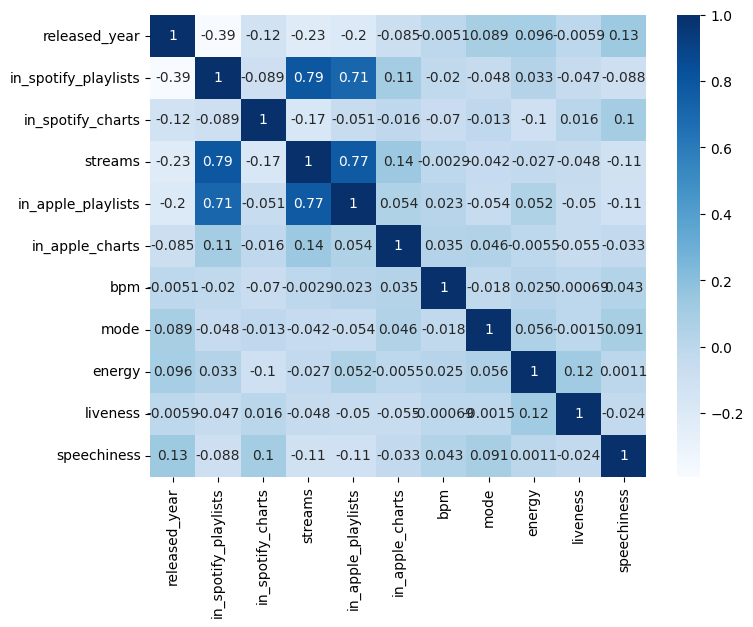

In [11]:
# Visualizing correlations among the remaining features.
import seaborn as sb

plt.figure(figsize=(8,6))
sb.heatmap(cl_data.corr(), cmap="Blues",annot=True)
plt.show()

In [12]:
# Streams, Apple playlist counts, and Spotify playlist counts are strongly correlated.
# To reduce redundancy in clustering,we are removing columns streams and Apple playlist counts, retaining Spotify playlist counts for now.

cl_data.drop(columns = ["in_apple_playlists", "streams"], inplace = True)

In [13]:
cl_data

,released_year,in_spotify_playlists,in_spotify_charts,in_apple_charts,bpm,mode,energy,liveness,speechiness
0,2023,553,147.0,263.0,125,0,83,8,4
1,2023,1474,48.0,126.0,92,0,74,10,4
2,2023,1397,113.0,207.0,138,0,53,31,6
3,2019,7858,3.0,207.0,170,0,72,11,15
4,2023,3133,50.0,133.0,144,1,80,11,6
...,...,...,...,...,...,...,...,...,...
948,2022,953,147.0,13.0,144,0,39,8,3
949,2022,1180,147.0,275.0,166,0,24,12,6
950,2022,573,147.0,275.0,92,0,67,8,6
951,2022,1320,147.0,26.0,97,0,77,12,5


#5. Outlier Analysis

We are inspecting each feature for outliers because extreme values can affect clustering. Features with a large proportion of outliers (more than 10%) are removed; otherwise, winsorization is considered.

In [14]:
# Defining a helper function for displaying boxplots.

def draw_boxplot(values, label):
    plt.boxplot(values)
    plt.xlabel(label)
    plt.show()

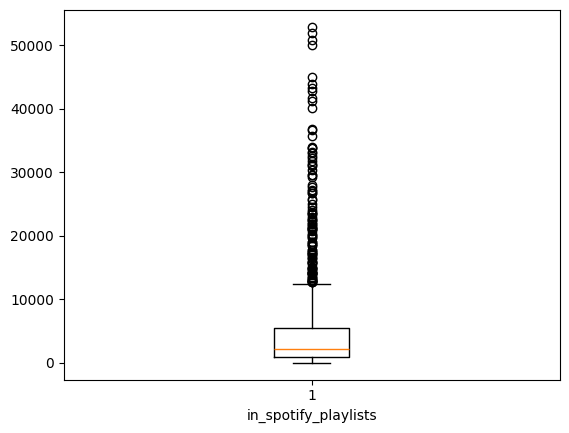

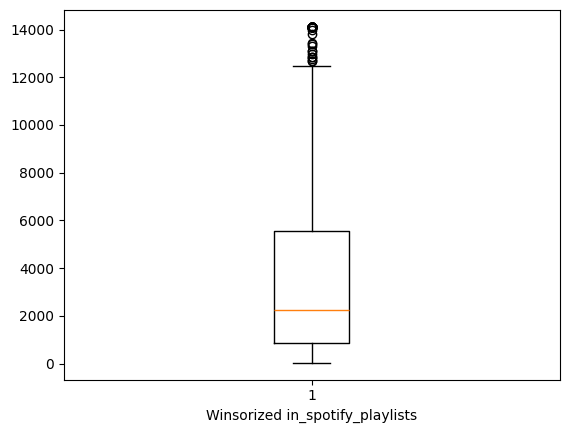

In [15]:
# Inspecting outliers in Spotify playlist counts.
from scipy.stats.mstats import winsorize

draw_boxplot(cl_data["in_spotify_playlists"], "in_spotify_playlists")

winsorized_data = winsorize(cl_data["in_spotify_playlists"], limits=[0.00, 0.10])
draw_boxplot(winsorized_data, "Winsorized in_spotify_playlists")
plt.show()

#Upper-tail winsorization at 10% does not eliminate all outliers in the original analysis, so this feature is removed.
cl_data.drop(columns = ["in_spotify_playlists"], inplace = True)

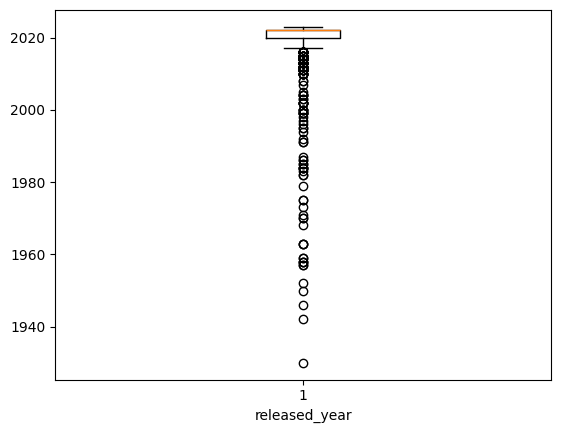

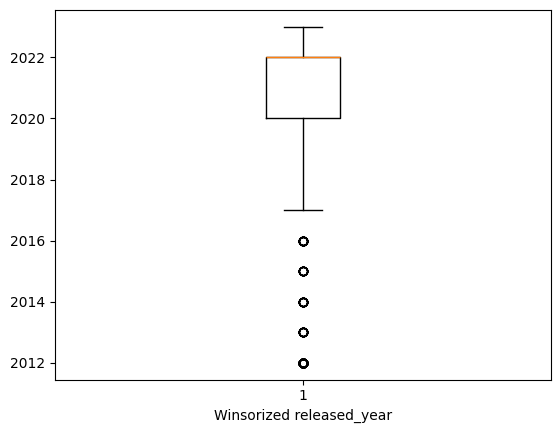

In [16]:
# Inspecting release-year outliers.

draw_boxplot(cl_data["released_year"], "released_year")

winsorized_data = winsorize(cl_data["released_year"], limits=[0.10, 0.00])
draw_boxplot(winsorized_data, "Winsorized released_year")

#Lower-tail winsorization at 10% does not eliminate all outliers in the original analysis, so release_year is removed.
cl_data.drop(columns = ["released_year"], inplace = True)

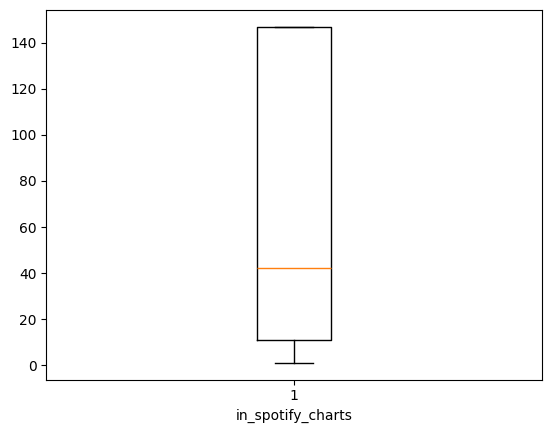

In [17]:
# Inspecting Spotify chart positions.

draw_boxplot(cl_data["in_spotify_charts"], "in_spotify_charts")

#The analysis identifies no outliers requiring changes.

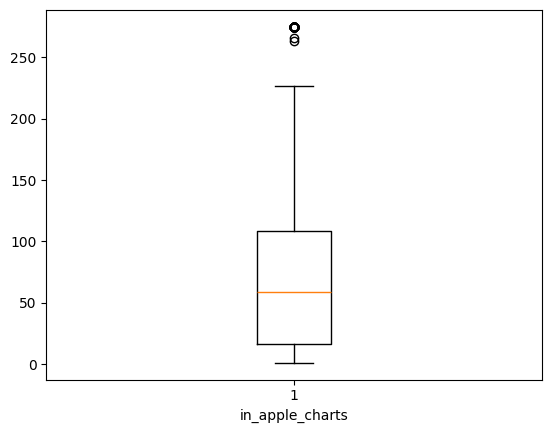

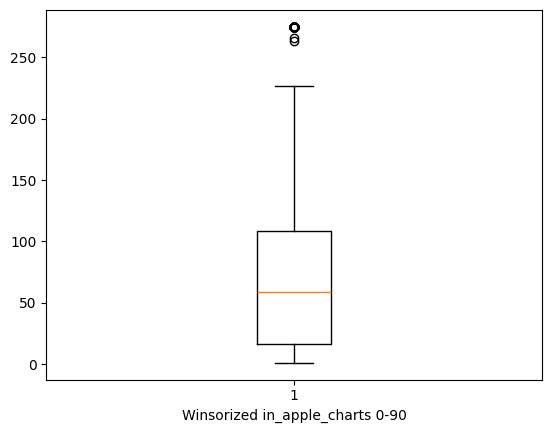

In [18]:
# Inspecting Apple chart positions.

draw_boxplot(cl_data["in_apple_charts"], "in_apple_charts")
winsorized_data = winsorize(cl_data["in_apple_charts"], limits=[0.00, 0.10])
draw_boxplot(winsorized_data, "Winsorized in_apple_charts 0-90")

# Upper-tail winsorization at 10% does not eliminate all outliers in the original analysis, so this feature is removed.
cl_data.drop(columns = ["in_apple_charts"], inplace = True)

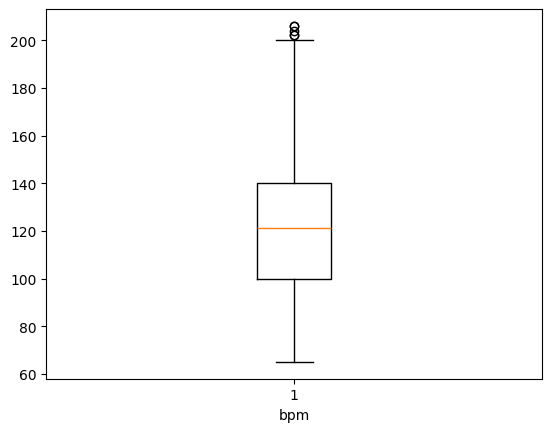

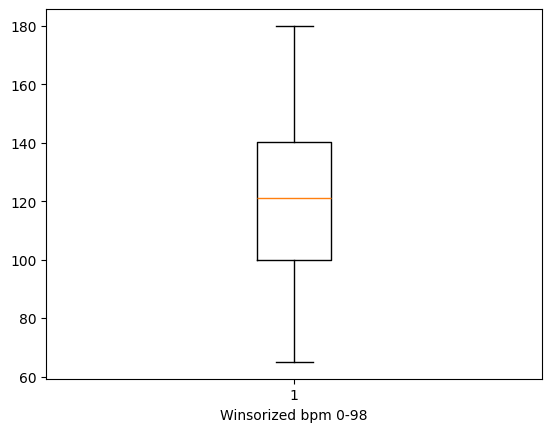

In [19]:
# Inspecting BPM.

draw_boxplot(cl_data["bpm"], "bpm")
winsorized_data = winsorize(cl_data["bpm"], limits=[0.00, 0.02])
draw_boxplot(winsorized_data, "Winsorized bpm 0-98")

#Upper-tail winsorization at 2% is used to limit the influence of extreme values, and the transformed values replace the original column.
cl_data["bpm"] = winsorized_data

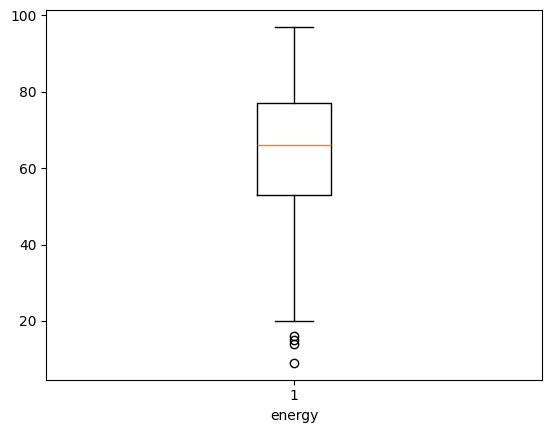

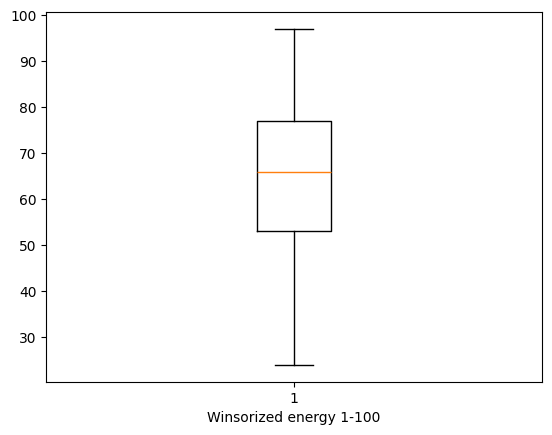

In [20]:
# Inspecting energy.

draw_boxplot(cl_data["energy"], "energy")
winsorized_data = winsorize(cl_data["energy"], limits=[0.01, 0.00])
draw_boxplot(winsorized_data, "Winsorized energy 1-100")

# Lower-tail winsorization at 1% is applied, and the transformed values replace the original column.
cl_data["energy"] = winsorized_data

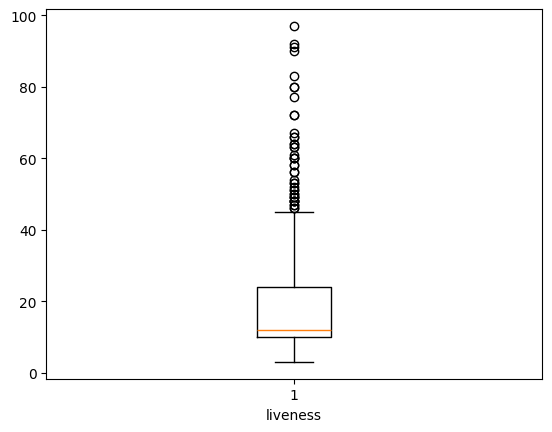

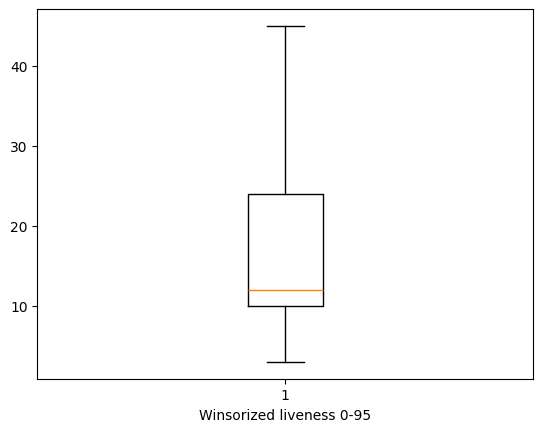

In [21]:
# Inspect liveness.

draw_boxplot(cl_data["liveness"], "liveness")
winsorized_data = winsorize(cl_data["liveness"], limits=[0.00, 0.05])
draw_boxplot(winsorized_data, "Winsorized liveness 0-95")

#  Upper-tail winsorization at 5% is applied, and the transformed values replace the original column.
cl_data["liveness"] = winsorized_data

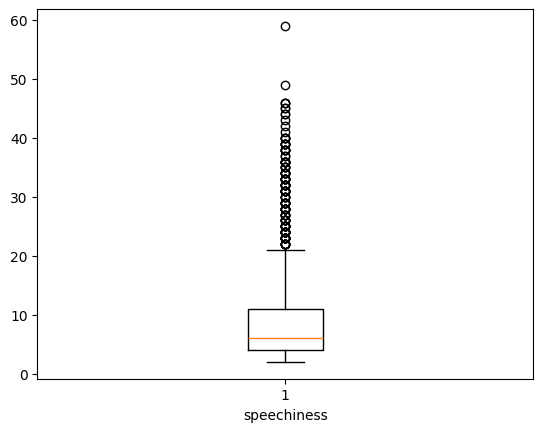

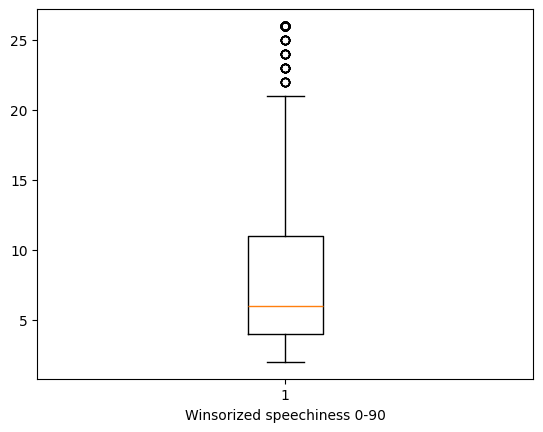

In [22]:
# Inspecting speechiness.

draw_boxplot(cl_data["speechiness"], "speechiness")
winsorized_data = winsorize(cl_data["speechiness"], limits=[0.00, 0.10])
draw_boxplot(winsorized_data, "Winsorized speechiness 0-90")

#  Upper-tail winsorization at 10% does not eliminate all outliers in the original analysis, so this feature is removed.
cl_data.drop(columns = ["speechiness"], inplace = True)

In [23]:
# Inspecting the cleaned dataset after missing-value handling, correlation screening, and outlier treatment.

cl_data.describe()
# Five features remain for clustering.

,in_spotify_charts,bpm,mode,energy,liveness
count,952.000000,952.000000,952.000000,952.000000,952.000000
mean,74.398109,122.316176,0.422269,64.359244,17.460084
std,64.622987,27.490861,0.494181,16.380695,11.231925
min,1.000000,65.000000,0.000000,24.000000,3.000000
25%,11.000000,99.750000,0.000000,53.000000,10.000000
50%,42.000000,121.000000,0.000000,66.000000,12.000000
75%,147.000000,140.250000,1.000000,77.000000,24.000000
max,147.000000,180.000000,1.000000,97.000000,45.000000


#6. Feature Scaling (Normalization)

In [24]:
# Normalizing features to the [0, 1] interval using MinMaxScaler because their original scales differ substantially.
# Converting the resulting NumPy array back into a DataFrame and checking the ranges.
from sklearn.preprocessing import MinMaxScaler

temp_data = MinMaxScaler().fit_transform(cl_data)
cl_data_scaled = pd.DataFrame(temp_data, columns = cl_data.columns)

cl_data_scaled.describe()

,in_spotify_charts,bpm,mode,energy,liveness
count,952.000000,952.000000,952.000000,952.000000,952.000000
mean,0.502727,0.498402,0.422269,0.552866,0.344288
std,0.442623,0.239051,0.494181,0.224393,0.267427
min,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.068493,0.302174,0.000000,0.397260,0.166667
50%,0.280822,0.486957,0.000000,0.575342,0.214286
75%,1.000000,0.654348,1.000000,0.726027,0.500000
max,1.000000,1.000000,1.000000,1.000000,1.000000


#7. Selecting the Number of Clusters Using the Elbow Method

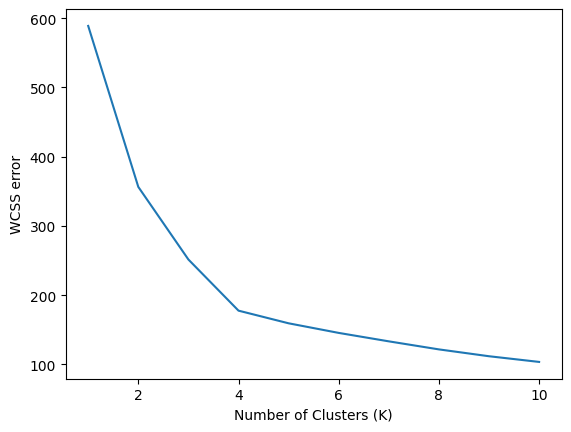

In [26]:
# We are applying the elbow method by fitting K-Means models for K = 1 through 10 and plotting within-cluster sum of squares (WCSS).
wcss = []

for i in range(1, 11):
    kmeans = cluster.KMeans(n_clusters=i, init='k-means++', max_iter=100, n_init=1000, random_state=0).fit(cl_data_scaled)
    wcss.append(kmeans.inertia_)

plt.plot(range(1, 11), wcss)
plt.xlabel("Number of Clusters (K)")
plt.ylabel("WCSS error")
plt.show()
# We can see that the elbow method showed us two possible outcomes for number of cluster. We will try out both of them.

#8. Fitting K-Means with 2 Clusters

In [37]:
# Fitting K-Means with two clusters and using k-means++ centroid initialization.
kmeans_2 = cluster.KMeans(
    n_clusters=2,
    init='k-means++',
    max_iter=100,
    n_init=20,
    random_state=0
)

X = cl_data_scaled.drop(columns='cluster', errors='ignore')
labels_2 = kmeans_2.fit_predict(X)

cl_data_2 = X.copy()
cl_data_2['cluster'] = labels_2

print(cl_data_2['cluster'].value_counts().sort_index())
print("Total songs:", len(cl_data_2))

cluster
0    402
1    550
Name: count, dtype: int64
Total songs: 952


In [38]:
cl_data_2

,in_spotify_charts,bpm,mode,energy,liveness,cluster
0,1.000000,0.521739,0.0,0.808219,0.119048,1
1,0.321918,0.234783,0.0,0.684932,0.166667,1
2,0.767123,0.634783,0.0,0.397260,0.666667,1
3,0.013699,0.913043,0.0,0.657534,0.190476,1
4,0.335616,0.686957,1.0,0.767123,0.190476,0
...,...,...,...,...,...,...
947,1.000000,0.686957,0.0,0.205479,0.119048,1
948,1.000000,0.878261,0.0,0.000000,0.214286,1
949,1.000000,0.234783,0.0,0.589041,0.119048,1
950,1.000000,0.278261,0.0,0.726027,0.214286,1


#9. Interpreting the Clusters: Sizes, Feature Profiles, and Dispersion

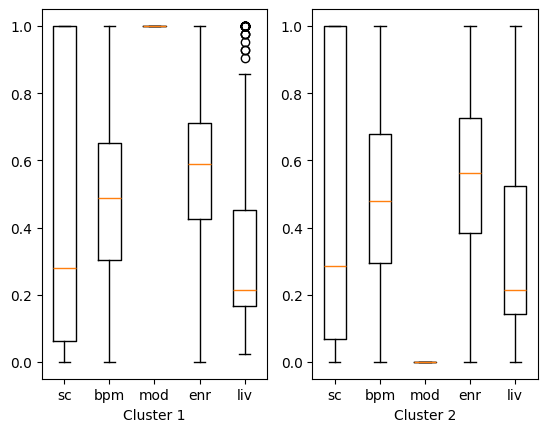

Cluster 1, N =  402
Cluster 2, N =  550


In [39]:
# Comparing the two clusters with boxplots and printting the number of songs assigned to each cluster.
fig, ax = plt.subplots(1,2)

ax[0].boxplot(cl_data_2[cl_data_2["cluster"]==0].drop(columns = "cluster"), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[0].set_xlabel("Cluster 1")

ax[1].boxplot(cl_data_2[cl_data_2["cluster"]==1].drop(columns = "cluster"), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[1].set_xlabel("Cluster 2")

plt.show()

print("Cluster 1, N = ", cl_data_2.loc[cl_data_2["cluster"]==0, "cluster"].count())
print("Cluster 2, N = ", cl_data_2.loc[cl_data_2["cluster"]==1, "cluster"].count())

 Interpretation of the two-cluster solution:
 1. **Cluster sizes**: Cluster 1 contains 402 songs and Cluster 2 contains 550; both groups are of comparable size.
 2. **Cluster profiles**: Cluster 1 contains Minor-mode songs (mode = 1), while Cluster 2 contains Major-mode songs (mode = 0). Energy is slightly lower in Cluster 2. Other feature profiles are very similar, so this separation may have limited substantive value.
 3. **Dispersion**: Both clusters show broadly similar dispersion. Cluster 2 is slightly more homogeneous for energy and liveness, but overall variability remains high. This motivates exploring a four-cluster solution.

#10. Repeating clustering with K = 4

In [40]:
# Refitting K-Means with four clusters and using k-means++ initialization.
kmeans_4 = cluster.KMeans(
    n_clusters=4,
    init='k-means++',
    max_iter=100,
    n_init=20,
    random_state=0
)

labels_4 = kmeans_4.fit_predict(X)

cl_data_4 = X.copy()
cl_data_4["cluster"] = labels_4

#11. Interpreting the Four-Cluster Solution

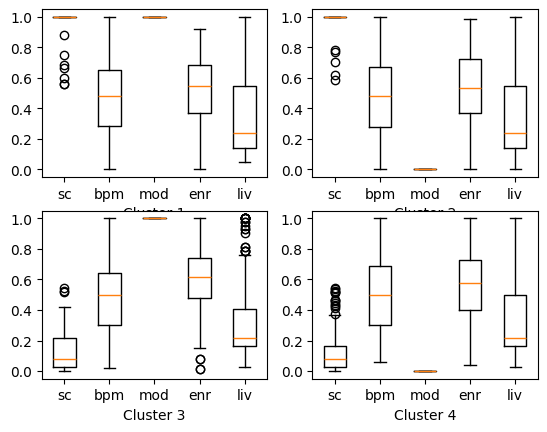

Cluster 1, N =  173
Cluster 2, N =  245
Cluster 3, N =  229
Cluster 4, N =  305


In [41]:
# Comparing the four clusters using boxplots.
fig, ax = plt.subplots(2,2)

ax[0,0].boxplot(cl_data_4[cl_data_4["cluster"]==0].drop(columns = ['cluster']), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[0,0].set_xlabel("Cluster 1")

ax[0,1].boxplot(cl_data_4[cl_data_4["cluster"]==1].drop(columns = ['cluster']), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[0,1].set_xlabel("Cluster 2")

ax[1,0].boxplot(cl_data_4[cl_data_4["cluster"]==2].drop(columns = ['cluster']), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[1,0].set_xlabel("Cluster 3")

ax[1,1].boxplot(cl_data_4[cl_data_4["cluster"]==3].drop(columns = ['cluster']), tick_labels=("sc", "bpm", "mod", "enr", "liv"))
ax[1,1].set_xlabel("Cluster 4")

plt.show()

print("Cluster 1, N = ", cl_data_4.loc[cl_data_4["cluster"]==0, "cluster"].count())
print("Cluster 2, N = ", cl_data_4.loc[cl_data_4["cluster"]==1, "cluster"].count())
print("Cluster 3, N = ", cl_data_4.loc[cl_data_4["cluster"]==2, "cluster"].count())
print("Cluster 4, N = ", cl_data_4.loc[cl_data_4["cluster"]==3, "cluster"].count())

Interpretation of the four-cluster solution:
1. **Cluster sizes**: The four clusters contain 229, 305, 173, and 245 songs, respectively; each is substantial.
2. **Cluster profiles**: Cluster 1 consists of lower-ranked Minor-mode songs, and Cluster 3 consists of lower-ranked Major-mode songs. Clusters 2 and 4 contain better-ranked Minor- and Major-mode songs, respectively. Better-ranked groups also have slightly higher energy.
3. **Dispersion**: Clusters 1 and 3 are relatively homogeneous in Spotify chart positions because they contain lower-ranked songs. Clusters 2 and 4 show greater variation in chart positions. Cluster 4 is comparatively more homogeneous for energy and liveness; other differences in dispersion are limited.

### Conclusion

K-Means clustering was used to group Spotify songs based on their musical characteristics and chart performance.

After data preprocessing, feature selection, outlier treatment, and normalization, two clustering solutions were explored: K = 2 and K = 4.

The results were analyzed by comparing cluster sizes, feature distributions, and variability within each group.

The analysis demonstrates how K-Means can identify similarities and differences between songs without using predefined class labels.